# Heuristics, LDA and NMF (TF-IDF) on reasoning traces

Companion to `trace_topics_base.ipynb` (embeddings + BERTopic).

**Contents**
1. **Lexicon / regex heuristics** — revision, hedging, numbers, JSON-ish fragments, excerpt/rule refs.
2. **LDA** on bag-of-words counts.
3. **NMF** on **TF-IDF**.

These are weaker on short reasoning sentences than embedding clusters, but useful as
transparent classical / lexical baselines for the seminar write-up.

## 0. Setup

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import LatentDirichletAllocation, NMF
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 200)

ROOT = Path.cwd().resolve()
if not (ROOT / "output").is_dir():
    ROOT = ROOT.parent

OUT = ROOT / "output"
DERIVED = ROOT / "analysis" / "derived"
SEED = 42
N_TOPICS = 10
DS = "DeepSeek-V4-Flash-0731"

RUN_DIRS = {
    "gpt-oss low": OUT / "gpt-oss-120b_low" / "1ebb0c8dc26d4681bda9555908104e67",
    "gpt-oss medium": OUT / "gpt-oss-120b_medium" / "8b438992f14c4b6da28ec581572dcc85",
    "gpt-oss high": OUT / "gpt-oss-120b_high" / "10d7970dd8304f8cb06d174a851f8e2a",
    "DeepSeek high": OUT / f"{DS}_high" / "2c50bb4fcde3462f9d6cbe6516b686c9",
    "DeepSeek max": OUT / f"{DS}_max" / "4c3229ed86dc4fe6b1ef4b95c64ca68d",
}
KEEP_RUNS = list(RUN_DIRS)

## 1. Load traces and split into sentences

Same units as the BERTopic notebook: sentences, not whole traces.

In [2]:
SPLIT = re.compile(r"\n+|(?<=[.!?])\s+(?=[A-Z\"'(\[])")


def sentences(text: str) -> list[str]:
    out = []
    for part in SPLIT.split(text or ""):
        part = re.sub(r"\s+", " ", part).strip(" -*•\t")
        if len(part.split()) >= 3:
            out.append(part)
    return out


rows = []
for run, run_dir in RUN_DIRS.items():
    for path in sorted((run_dir / "reasoning_traces").glob("*.jsonl")):
        with path.open(encoding="utf-8") as f:
            for i, line in enumerate(f):
                c = json.loads(line)
                reasoning = c.get("reasoning_content")
                if not reasoning or not str(reasoning).strip():
                    continue
                rows.append({
                    "run": run,
                    "report": Path(str(c["pdf"]).replace("\\", "/")).name,
                    "call_index": i,
                    "reasoning": reasoning,
                })

pages = pd.DataFrame(rows)
pages["run"] = pd.Categorical(pages["run"], KEEP_RUNS, ordered=True)
pages["trace_id"] = np.arange(len(pages))

seg = pd.DataFrame(
    [
        (row.trace_id, row.run, i, text)
        for row in pages.itertuples()
        for i, text in enumerate(sentences(row.reasoning))
    ],
    columns=["trace_id", "run", "pos", "text"],
)
seg["run"] = pd.Categorical(seg["run"], KEEP_RUNS, ordered=True)

print(f"{len(pages):,} traces  |  {len(seg):,} sentences  |  {seg.text.nunique():,} unique")
display(seg.groupby("run", observed=True).size().rename("sentences").to_frame())

4,858 traces  |  226,557 sentences  |  130,169 unique


,sentences
run,
gpt-oss low,3728
gpt-oss medium,13033
gpt-oss high,97973
DeepSeek high,44536
DeepSeek max,67287


## 2. Simple heuristics

Transparent markers (adapted from `run_comparison.ipynb`).  
We report **share of sentences** that match, so runs with different lengths stay comparable.

In [3]:
PATTERNS = {
    "revision": re.compile(
        r"\b(?:wait|actually|hmm+|on second thought|double[- ]?check\w*|"
        r"re-?check\w*|re-?examin\w*|reconsider\w*|let me verify|let me rethink)\b",
        re.I,
    ),
    "hedge": re.compile(
        r"\b(?:maybe|perhaps|probably|possibly|likely|unclear|ambiguous|"
        r"not sure|uncertain|might|could be)\b",
        re.I,
    ),
    "number": re.compile(r"(?<!\w)\d[\d,. ]*\d|\b\d\b"),
    "jsonish": re.compile(r"\{|\}|KPI_Entries|\b(?:year|unit|kpi_name)\b\s*:?", re.I),
    "excerpt_ref": re.compile(
        r"\b(?:excerpt|table|page|row|column|according to the|in the text|from the report)\b",
        re.I,
    ),
    "rule_ref": re.compile(
        r"\b(?:instruction|rule|should|must|only extract|do not|don't include|scope)\b",
        re.I,
    ),
}

for name, pat in PATTERNS.items():
    seg[name] = seg["text"].str.contains(pat, na=False)

# Also at trace level: markers per 1k words (closer to run_comparison).
trace_text = pages.set_index("trace_id")["reasoning"].fillna("")
words = trace_text.str.split().str.len().replace(0, np.nan)
trace_feats = pd.DataFrame({"run": pages.set_index("trace_id")["run"]})
for name, pat in PATTERNS.items():
    counts = trace_text.str.count(pat)
    trace_feats[f"{name}_per_1k"] = counts / words * 1000

sent_share = seg.groupby("run", observed=True)[list(PATTERNS)].mean()
display(sent_share.style.format("{:.1%}").set_caption("Share of sentences matching each heuristic"))

trace_mean = trace_feats.groupby("run", observed=True)[[c for c in trace_feats.columns if c.endswith("_per_1k")]].mean()
display(trace_mean.style.format("{:.2f}").set_caption("Mean markers per 1k words (trace level)"))

,revision,hedge,number,jsonish,excerpt_ref,rule_ref
run,,,,,,
gpt-oss low,1.0%,9.5%,24.2%,7.0%,22.7%,7.3%
gpt-oss medium,0.8%,12.6%,38.3%,21.8%,19.4%,32.3%
gpt-oss high,1.6%,7.7%,39.8%,14.6%,8.3%,27.0%
DeepSeek high,3.7%,14.8%,46.2%,10.6%,14.8%,23.8%
DeepSeek max,3.0%,21.4%,47.2%,11.1%,13.3%,24.6%


,revision_per_1k,hedge_per_1k,number_per_1k,jsonish_per_1k,excerpt_ref_per_1k,rule_ref_per_1k
run,,,,,,
gpt-oss low,0.37,8.31,27.71,6.19,51.96,4.90
gpt-oss medium,0.30,12.60,77.75,55.78,29.02,55.51
gpt-oss high,1.91,5.27,67.81,35.06,13.52,34.16
DeepSeek high,0.82,5.59,61.74,42.54,36.75,15.28
DeepSeek max,0.66,9.74,60.36,40.92,35.25,15.35


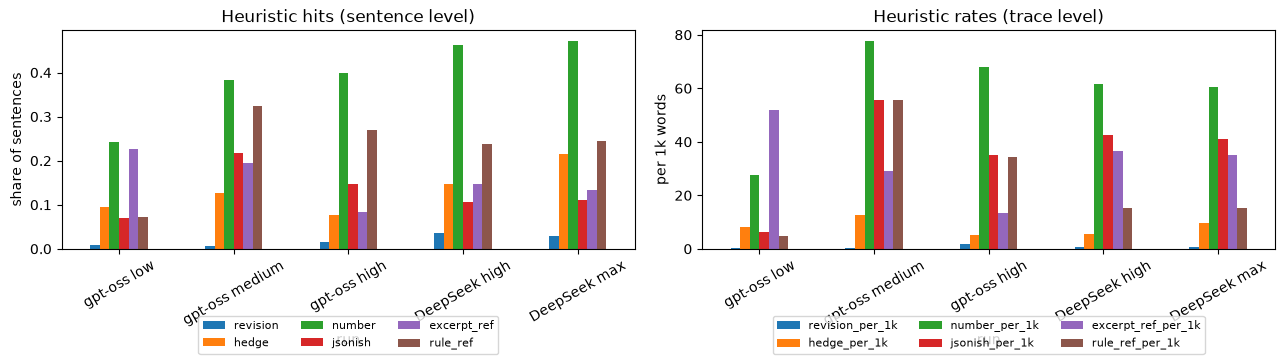

revision (4987 unique sentences)
- Wait footnote *2 says "based on the total amount of energy (electricity, petroleum, and gas) consumed in the production process." So yes includes electricity.
- Actually "Excluding JVs" means only consolidated companies; "Including JVs" includes joint ventures where the company has operational control?
- Wait "" is 2013?
- Actually "C"->"D", "O"->"P", "2" stays "2"?
- Actually T is under 5?
hedge (25400 unique sentences)
- This suggests "137,2 140,8" might be for the first of the two scopes (Scope 1), and "136,7 133,4" for the second (Scope 2)?
- Let's scan: mentions "0g CO₂e/kWh" emission factor, "1." maybe?
- The raw text "Metric tonnes of CO2" might be a truncation of "Thousand metric tonnes of CO2" because the word "Thousand" is in a separate text box not captured.
- Need maybe extract "Scope1 Total" as "1" kpi_name.
- That could be a total column for FY2019?


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sent_share.plot(kind="bar", ax=axes[0])
axes[0].set_ylabel("share of sentences")
axes[0].set_title("Heuristic hits (sentence level)")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=3, fontsize=8)
axes[0].tick_params(axis="x", rotation=30)

trace_mean.plot(kind="bar", ax=axes[1])
axes[1].set_ylabel("per 1k words")
axes[1].set_title("Heuristic rates (trace level)")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=3, fontsize=8)
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

# Quick peek: example revision / hedge sentences
for name in ("revision", "hedge"):
    hits = seg[seg[name]].drop_duplicates("text")
    print("=" * 80)
    print(name, f"({len(hits)} unique sentences)")
    for s in hits.sample(min(5, len(hits)), random_state=SEED).text:
        print("-", s)

## 3. Bag-of-words matrices

- **LDA** wants raw counts → `CountVectorizer`
- **NMF** works well with **TF-IDF** → `TfidfVectorizer`

We fit on **unique sentences** (like BERTopic) so repeated boilerplate does not dominate as much.
Short sentences + little word overlap still limit how clean these topics get.

In [5]:
uniq = seg["text"].drop_duplicates().tolist()
print(f"fitting on {len(uniq):,} unique sentences")

count_vec = CountVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.9,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z\-]+\b",
)
X_counts = count_vec.fit_transform(uniq)

tfidf_vec = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.9,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z\-]+\b",
)
X_tfidf = tfidf_vec.fit_transform(uniq)

print("count matrix:", X_counts.shape, " | tf-idf matrix:", X_tfidf.shape)


def top_words(model, feature_names, n=8):
    rows = []
    for k, comp in enumerate(model.components_):
        idx = comp.argsort()[::-1][:n]
        rows.append({
            "topic": k,
            "keywords": ", ".join(feature_names[i] for i in idx),
        })
    return pd.DataFrame(rows)

fitting on 130,169 unique sentences
count matrix: (130169, 19006)  | tf-idf matrix: (130169, 19006)


## 4. LDA (counts)

Each document (sentence) gets a topic distribution; we take the **argmax** topic for plotting.

In [6]:
lda = LatentDirichletAllocation(
    n_components=N_TOPICS,
    random_state=SEED,
    learning_method="batch",
    max_iter=20,
)
lda_doc = lda.fit_transform(X_counts)
lda_topics = lda_doc.argmax(axis=1)

lda_info = top_words(lda, count_vec.get_feature_names_out())
lda_info["n_unique"] = pd.Series(lda_topics).value_counts().sort_index().to_numpy()
display(lda_info)

# Map back to all sentence occurrences
uniq_map = pd.DataFrame({"text": uniq, "lda_topic": lda_topics})
seg = seg.merge(uniq_map, on="text", how="left")

# Show a few example sentences per topic
for topic in range(N_TOPICS):
    g = seg[seg.lda_topic == topic].drop_duplicates("text")
    print("=" * 80)
    print(f"LDA topic {topic} | {lda_info.loc[topic, 'keywords']}")
    for s in g.sample(min(3, len(g)), random_state=SEED).text:
        print("-", s)

,topic,keywords,n_unique
0,0,"scope, total, scope scope, values, extract, emissions, location-based, scope total",21958
1,1,"absolute, emissions, values, total, absolute values, total emissions, need, consider",10435
2,2,"group, output, json, fiscal, year, emissions, fiscal year, object",10732
3,3,"excerpt, numbers, includes, emissions, report, data, values, excerpt includes",14339
4,4,"maybe, need, include, need maybe, numbers, years, values, maybe include",15821
5,5,"values, scope, table, let, ensure, need, need ensure, check",9692
6,6,"emissions, scope, ghg, ghg emissions, direct, indirect, total, footnote",12108
7,7,"energy, consumption, electricity, energy consumption, use, emissions, fuel, let",11370
8,8,"extract, values, company, says, extract values, tons, metric, sum",11377
9,9,"unit, year, value, tonnes, value unit, report, entries, output",12337


LDA topic 0 | scope, total, scope scope, values, extract, emissions, location-based, scope total
- Need maybe extract "46.3" as "Scope 2 (location-based)"?
- Scope 3: 4.708 tCO2e
- Possibly it's the same scope as the first row (maybe Scope 1).
LDA topic 1 | absolute, emissions, values, total, absolute values, total emissions, need, consider
- Schema enum says "1".
- No, schema only KPI_Entries.
- But 9th number is 1, not 2.
LDA topic 2 | group, output, json, fiscal, year, emissions, fiscal year, object
- For example, we have been jointly working with Tohoku University on a process to synthesize the precursor for plastics called dimethyl carbonate from CO2 since 2007 and have commercialized it.
- That seems plausible?
- It says "Global CO2 Emissions in Fiscal Year 2016" in plain.
LDA topic 3 | excerpt, numbers, includes, emissions, report, data, values, excerpt includes
- The excerpt includes "4/4 factories 100%" but that's not CO2.
- Then for 6 emission categories, also 12 numbers.
- T

## 5. NMF (TF-IDF)

Same idea as LDA, but factors a TF-IDF matrix. Often a bit sharper keywords than LDA on short text.

In [7]:
nmf = NMF(
    n_components=N_TOPICS,
    random_state=SEED,
    init="nndsvda",
    max_iter=400,
)
nmf_doc = nmf.fit_transform(X_tfidf)
nmf_topics = nmf_doc.argmax(axis=1)

nmf_info = top_words(nmf, tfidf_vec.get_feature_names_out())
nmf_info["n_unique"] = pd.Series(nmf_topics).value_counts().sort_index().to_numpy()
display(nmf_info)

uniq_map_nmf = pd.DataFrame({"text": uniq, "nmf_topic": nmf_topics})
seg = seg.merge(uniq_map_nmf, on="text", how="left")

for topic in range(N_TOPICS):
    g = seg[seg.nmf_topic == topic].drop_duplicates("text")
    print("=" * 80)
    print(f"NMF topic {topic} | {nmf_info.loc[topic, 'keywords']}")
    for s in g.sample(min(3, len(g)), random_state=SEED).text:
        print("-", s)

,topic,keywords,n_unique
0,0,"scope, scope scope, total scope, scope total, scope emissions, values scope, scope values, maybe scope",12594
1,1,"values, absolute, absolute values, values scope, scope values, total values, need, extract absolute",10609
2,2,"maybe, need, need maybe, include, maybe include, include scope, maybe scope, maybe extract",8898
3,3,"total, total scope, scope total, total emissions, total values, values total, available, subcategories",9326
4,4,"unit, year, value, value unit, year value, tonnes, location-based value, unit tonnes",11299
5,5,"emissions, total emissions, ghg, ghg emissions, scope emissions, tons, direct, absolute",27929
6,6,"extract, company, extract values, sum, need extract, says, says extract, scopes",11713
7,7,"numbers, excerpt, includes, excerpt includes, emission, report, like, numbers like",24831
8,8,"output, json, output json, object, json object, need, list, entries",7040
9,9,"location-based, market-based, scope location-based, market-based location-based, value, assume, scope market-based, mentioned",5930


NMF topic 0 | scope, scope scope, total scope, scope total, scope emissions, values scope, scope values, maybe scope
- 2018: 5,306; 878; 4,428; 238; 564; 26; 3600
- Both are separate.
- That is "3FUVSO".
NMF topic 1 | values, absolute, absolute values, values scope, scope values, total values, need, extract absolute
- Here the values are in the same order as the series labels: Elec-Abs, Elec-LfL, Fuel-Abs, Fuel-LfL.
- But we need to double-check if there might be any hidden values like "tCO2e" or "tonnes" in the excerpt.
- But we need whole company values.
NMF topic 2 | maybe, need, need maybe, include, maybe include, include scope, maybe scope, maybe extract
- Need maybe include "Scope 2 (location-based)" for both years.
- Actually "98,169" in metric tonnes, maybe "98,169" no trailing.
- Need maybe include "59.5" as 2018.
NMF topic 3 | total, total scope, scope total, total emissions, total values, values total, available, subcategories
- It could be the total Scope 3 for the company 

## 6. Compare topic mix by run

Shares within each run (comparable). If LDA/NMF pick up real shifts, bars move —
but expect noisier / less interpretable topics than BERTopic.

run,gpt-oss low,gpt-oss medium,gpt-oss high,DeepSeek high,DeepSeek max
lda_topic,,,,,
0,17.6%,18.1%,11.2%,19.7%,17.4%
1,6.5%,11.2%,8.2%,8.4%,7.6%
2,1.5%,12.7%,8.4%,10.5%,8.8%
3,16.6%,17.1%,23.9%,6.8%,6.0%
4,8.2%,7.3%,7.3%,12.0%,14.9%
5,10.8%,5.4%,11.8%,7.2%,6.7%
6,2.9%,3.5%,3.8%,8.4%,9.9%
7,1.7%,3.3%,6.0%,8.1%,8.5%
8,5.0%,6.8%,6.9%,8.2%,9.2%


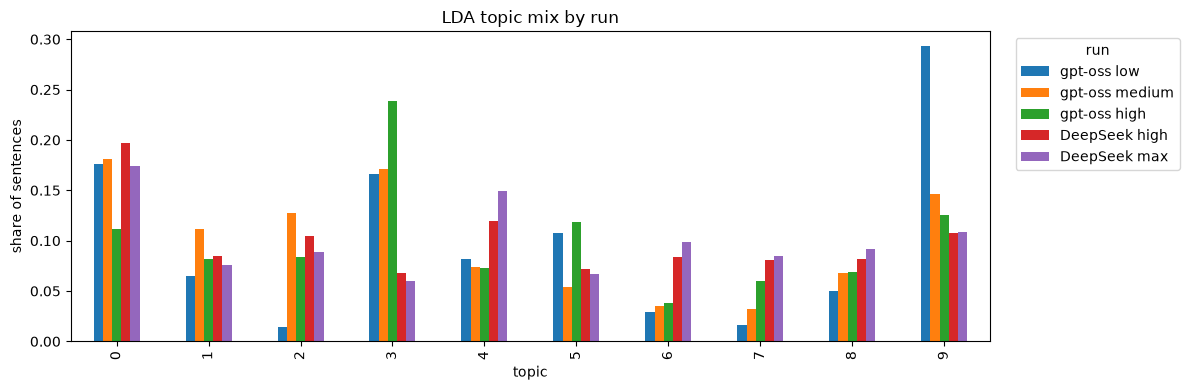

run,gpt-oss low,gpt-oss medium,gpt-oss high,DeepSeek high,DeepSeek max
nmf_topic,,,,,
0,3.2%,6.3%,7.0%,11.4%,9.1%
1,6.5%,9.2%,10.8%,8.6%,7.5%
2,1.3%,2.7%,5.0%,6.0%,11.2%
3,6.7%,4.3%,4.1%,6.8%,7.1%
4,6.8%,8.4%,7.7%,6.4%,6.9%
5,9.0%,10.5%,14.0%,18.6%,19.4%
6,23.1%,6.8%,5.7%,11.3%,11.1%
7,12.6%,18.4%,29.1%,14.3%,11.9%
8,26.7%,24.1%,12.5%,12.8%,11.9%


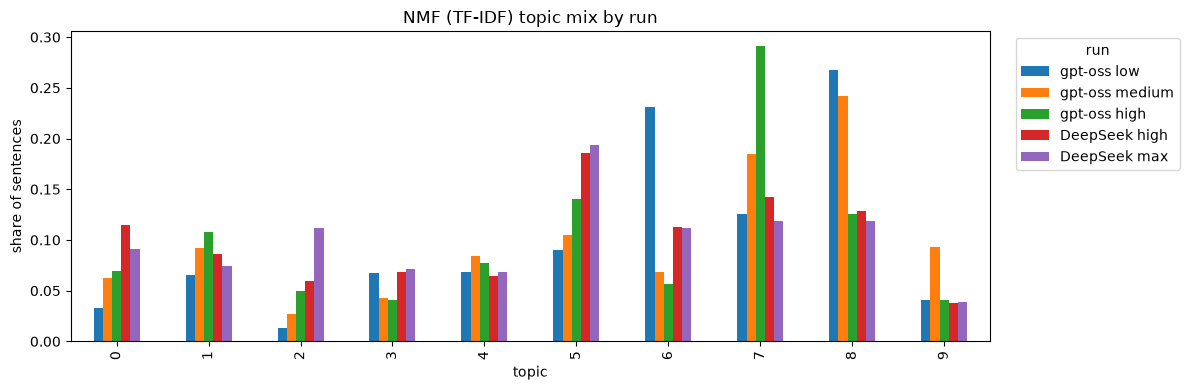

In [8]:
def plot_topic_mix(topic_col: str, title: str):
    share = (
        seg.groupby(["run", topic_col], observed=True).size()
           .groupby("run", observed=True).transform(lambda s: s / s.sum())
           .rename("share")
           .reset_index()
    )
    pivot = (
        share.pivot(index=topic_col, columns="run", values="share")
             .fillna(0)
             .reindex(columns=KEEP_RUNS)
    )
    display(pivot.style.format("{:.1%}").set_caption(title))

    ax = pivot.plot(kind="bar", figsize=(12, 4))
    ax.set_ylabel("share of sentences")
    ax.set_xlabel("topic")
    ax.set_title(title)
    ax.legend(title="run", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
    return pivot


lda_pivot = plot_topic_mix("lda_topic", "LDA topic mix by run")
nmf_pivot = plot_topic_mix("nmf_topic", "NMF (TF-IDF) topic mix by run")

## 7. Side-by-side: heuristics vs classical topics vs embeddings

| Method | Input | Strength | Weakness here |
|---|---|---|---|
| Heuristics | regex / lexicon | interpretable, cheap | only finds what you predefined |
| LDA (counts) | bag-of-words | classic baseline | short sentences, sparse words |
| NMF (TF-IDF) | TF-IDF | often clearer keywords than LDA | still lexical, no deep semantics |
| BERTopic / MiniLM (`trace_topics_base.ipynb`) | embeddings | groups paraphrases | labels still need human reading |

For the write-up: use heuristics for concrete claims ("more revision markers"),
embeddings/BERTopic for open structure, and LDA/NMF as the classical baseline that
usually looks weaker on this data.

## 8. UMAP point clouds for LDA / NMF topics

UMAP on the **TF-IDF** vectors (same input as NMF), coloured once by LDA topic and once by NMF topic.
These are classical bag-of-words clusters — expect more overlap than with MiniLM/BERTopic.

Optional: define groups in `LDA_TOPIC_LABELS` / `NMF_TOPIC_LABELS` below after reading the keywords.

/Users/reginapichler/Documents/Uni/Master/Seminar/gist-reasoning-traces/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/reginapichler/Documents/Uni/Master/Seminar/gist-reasoning-traces/.venv/lib/python3.13/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/reginapichler/Documents/Uni/Mast

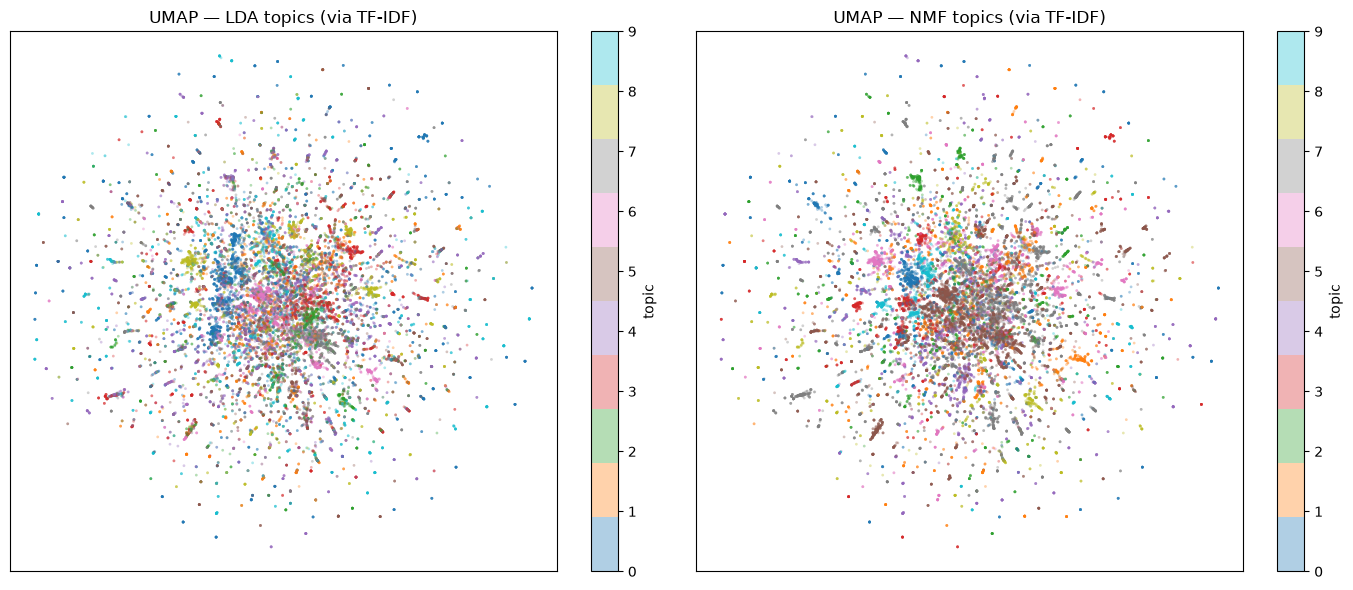

LDA labels:


,topic,label
0,0,LDA 0
1,1,LDA 1
2,2,LDA 2
3,3,LDA 3
4,4,LDA 4
5,5,LDA 5
6,6,LDA 6
7,7,LDA 7
8,8,LDA 8
9,9,LDA 9


NMF labels:


,topic,label
0,0,NMF 0
1,1,NMF 1
2,2,NMF 2
3,3,NMF 3
4,4,NMF 4
5,5,NMF 5
6,6,NMF 6
7,7,NMF 7
8,8,NMF 8
9,9,NMF 9


In [9]:
from umap import UMAP

# Fill in after inspecting LDA/NMF keywords (optional). Until then we colour by topic id.
LDA_TOPIC_LABELS = {i: f"LDA {i}" for i in range(N_TOPICS)}
NMF_TOPIC_LABELS = {i: f"NMF {i}" for i in range(N_TOPICS)}
# Example once you have labels:
# LDA_TOPIC_LABELS = {0: "Intensity / power", 1: "Scope 2 subtypes", ...}

DERIVED_CLASSICAL = DERIVED / "topics_lda_nmf"
DERIVED_CLASSICAL.mkdir(parents=True, exist_ok=True)
umap_path = DERIVED_CLASSICAL / "umap2d_tfidf.npy"

if umap_path.exists() and len(np.load(umap_path)) == X_tfidf.shape[0]:
    xy = np.load(umap_path)
else:
    # Dense projection of TF-IDF for UMAP (truncate features for speed/memory).
    from sklearn.decomposition import TruncatedSVD
    X_red = TruncatedSVD(n_components=50, random_state=SEED).fit_transform(X_tfidf)
    xy = UMAP(
        n_neighbors=15, n_components=2, min_dist=0.1,
        metric="cosine", random_state=SEED,
    ).fit_transform(X_red)
    np.save(umap_path, xy)

plot = pd.DataFrame({
    "text": uniq,
    "lda_topic": lda_topics,
    "nmf_topic": nmf_topics,
    "x": xy[:, 0],
    "y": xy[:, 1],
})
plot["lda_label"] = plot.lda_topic.map(LDA_TOPIC_LABELS)
plot["nmf_label"] = plot.nmf_topic.map(NMF_TOPIC_LABELS)

rng = np.random.default_rng(SEED)
idx = rng.choice(len(plot), size=min(25_000, len(plot)), replace=False)
sub = plot.iloc[idx]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, col, title in [
    (axes[0], "lda_topic", "UMAP — LDA topics (via TF-IDF)"),
    (axes[1], "nmf_topic", "UMAP — NMF topics (via TF-IDF)"),
]:
    sc = ax.scatter(sub.x, sub.y, c=sub[col], cmap="tab10", s=4, alpha=0.35, linewidths=0)
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(sc, ax=ax, ticks=range(N_TOPICS)).set_label("topic")
plt.tight_layout()
plt.show()

print("LDA labels:")
display(pd.DataFrame({"topic": range(N_TOPICS), "label": [LDA_TOPIC_LABELS[i] for i in range(N_TOPICS)]}))
print("NMF labels:")
display(pd.DataFrame({"topic": range(N_TOPICS), "label": [NMF_TOPIC_LABELS[i] for i in range(N_TOPICS)]}))